<center>

## ARHITEKTURE NEURONSKIH MREŽA
## Vježba 2 <br>**Perceptron**



</center>



📣 **PERCEPTRON** je osnovna građevna jedinica *svake neuronske mreže*.

#### ANALOGIJA S BIOLOŠKIM NEURONOM


Perceptron je zapravo *pojednostavljeni, matematički model* biološkog neurona.

Neuron | Perceptron
-|-
Prima signale od drugih neurona (*dendrite*) | Prima $n$ ulaznih signala
Obrađuje signale u jezgri (*nucleus*) | Vrši izračun nad tim ulaznim signalima
Šalje informaciju drugim stanicama (*axon terminal*) | Provlači rezultat tog izračuna kroz **nelinearnu** funkciju koja daje jedan izlaz $\to$ **aktivaciju** perceptrona za dane ulaze

<img src = 'https://drive.google.com/uc?id=18vtm0yiLk-4lchtXL8IHA0AkUzD7MotG' width='400px'/> | <img src='https://drive.google.com/uc?id=12ephGygcm8GuqVNk4SoqJMcgqybqU7IP' width='400px' />

## Kako radi perceptron?

---

Oznake:

- $x_i$ je $i$-ti ulaz
- $w_i$ je težinski faktor $i$-tog ulaza
- $\varphi$ je ***nelinearna*** funkcija koju nazivamo **aktivacijskom funkcijom**

Algoritam:

1. Množimo sve $x_i$ s $w_i$
2. Zbrojimo sve umnoške $x_i\cdot w_i$
3. Taj zbroj ulazi u aktivacijsku funkciju
4. Aktivacijska funkcija proizvodi izlaz - **aktivaciju** neurona

### Čemu služi aktivacijska funkcija?

- Aktivacijska funkcija je **nelinearna** funkcija; njen graf nije pravac.
- Nelinearna aktivacijska funkcija omogućava višeslojnim perceptronima učenje kompleksnijih preslikavanja.
- Ovdje koristimo vrlo jednostavnu aktivacijsku funkciju - **step funkciju**:



$$S(x)=
\begin{cases}
    1, & \text{ako je } x\geq 0\\
    0, & \text{u protivnom}.
\end{cases}$$
<br><br>
<center>
<img src = 'https://upload.wikimedia.org/wikipedia/commons/a/af/Asymptote_Heaviside_function.png' width='300px'/>
</center>

**Napomena**

---

 Neka su
- $\boldsymbol{x} = (x_1, x_2, \dots, x_n) \in \mathbb{R}^n$ vektor ulaznih vrijednosti
- $\boldsymbol{w} = (w_1, w_2, \dots, w_n) \in \mathbb{R}^n$ vektor odgovarajućih težina.

Tada vrijednost koju računa neuron i šalje u aktivacijsku funkciju možemo dobiti kao skalarni produkt $$\langle \boldsymbol{x}, \boldsymbol{w}\rangle = \sum\limits_i^n x_iw_i \in \mathbb{R}.$$
 Dakle, aktivacija neurona bit će jednaka $\varphi(\langle \boldsymbol{x}, \boldsymbol{w}\rangle)$.
 <br><br>

 **Matrična notacija:**
 <br><br>
 $$\boldsymbol{x} = \begin{bmatrix}x_1 \\ x_2 \\ \vdots \\ x_n\end{bmatrix}, \quad \boldsymbol{w} = \begin{bmatrix} w_1 \\ w_2 \\ \vdots \\ w_n \end{bmatrix}\implies   \text{aktivacija} =  \varphi(\boldsymbol{x}^T \boldsymbol{w}).$$



## Implementacija u Pythonu

### Bazna klasa

In [1]:
""" Do not change. """

from abc import ABC, abstractmethod
import numpy as np

class Perceptron(ABC):
    """ Base class for our perceptrons."""
    def __init__(self, lr=0.5, epochs=100):
        """ Constructor. """
        self.learning_rate = lr
        self.epochs = epochs
        self.weights = None
    def evaluate(self, X, y):
        """ Get prediction accuracy against a test set. """
        predictions = self.predict(X)
        return np.count_nonzero(predictions == y) / y.shape[0]          # točnost: broj točnih/ukupno
    def predict(self, X):
        """ Predict labels for a list of inputs. """
        predictions = []
        for x in X:
            prediction = 0 if np.dot(self.weights, x) < 0 else 1        # implementacija step funkcije
            predictions.append(prediction)
        return np.array(predictions)
    @abstractmethod
    def fit(self):
        """ Abstract training method. """
        pass

### Jednostavni perceptron

In [2]:
""" Do not change. """

class SimplePerceptron(Perceptron):
    """
    Simple perceptron.
    Extends the abstract class above by implementing fit().
    """
    def fit(self, X, y):
        """ Simple perceptron training. """
        self.weights = np.random.randn(X.shape[1])
        self.weight_history = []
        for epoch in range(self.epochs):
            # the training data is shuffled every epoch
            the_data = list(zip(X, y))
            np.random.shuffle(the_data)
            for x, label in the_data:
                # attempt prediction
                prediction = 0 if np.dot(self.weights, x) < 0 else 1
                # if the prediction fails, update the weights
                if prediction != label:
                    update = self.learning_rate * (label - prediction) * x
                    self.weights += update
            self.weight_history.append(np.copy(self.weights))

### AveragedPerceptron
> *Zadaća: Zadatak 1*

In [3]:
class AveragedPerceptron(Perceptron):
    """
    Averaged perceptron.
    Must extend the abstract class by implementing fit().
    The fit() for AveragedPerceptron is very similar to the one by SimplePerceptron.
    """
    def fit(self, X, y):
        self.weights = np.random.randn(X.shape[1])
        self.weight_history = []
        # running sum of the weight vector after every example (updated or not)
        weight_sum = np.zeros_like(self.weights)
        steps = 0
        for epoch in range(self.epochs):
            the_data = list(zip(X, y))
            np.random.shuffle(the_data)
            for x, label in the_data:
                prediction = 0 if np.dot(self.weights, x) < 0 else 1
                if prediction != label:
                    self.weights += self.learning_rate * (label - prediction) * x
                weight_sum += self.weights
                steps += 1
            self.weight_history.append(weight_sum / steps)
        if steps > 0:
            self.weights = weight_sum / steps

### [Breast Cancer Wisconsin (Diagnostic)](https://archive.ics.uci.edu/ml/datasets/Breast+Cancer+Wisconsin+(Diagnostic))
    - 569 instanci podataka
    - 30 numeričkih značajki/dijagnostičkih mjerenja

In [4]:
import numpy as np

In [5]:
""" Do not change. """
# the breast cancer dataset
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()

In [6]:
print(data.DESCR)

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [7]:
X = np.array(data['data'])  # data points
print(f'X shape: {X.shape}')
y = np.array(data['target'])  # labels
print('Labels: {}'.format(np.unique(y)))
print('Class names: {}'.format(data['target_names']) )

X shape: (569, 30)
Labels: [0 1]
Class names: ['malignant' 'benign']


In [8]:
b = np.ones_like(y)  # bias
X = np.column_stack((X, b))  # gets glued to data

In [9]:
b.shape

(569,)

In [10]:
b

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [11]:
from tqdm import tqdm
# x- and y-axis values for plotting
xs = []
ys_averaged = []
ys_simple = []

# stack the data together for shuffling
the_data = np.column_stack((X, y))
# 50% of the data for training, 50% for testing
cutoff = len(the_data) // 2

# test these epoch numbers
for epochs in tqdm(range(0, 151, 5)):
    xs.append(epochs)
    scores_averaged = []
    scores_simple = []

    # do 10 runs for each epoch
    for experiments in range(0, 10):

        # prepare training and test data
        # the data is randomly shuffled for each experiment
        np.random.shuffle(the_data)
        # bez zadnja dva retka (bias i labele)
        X_train = the_data[:cutoff,:-2] # -1 ako zelim uhvatiti 1icu za bias
        y_train = the_data[:cutoff,-1]
        X_test = the_data[cutoff:,:-2]  # -1 ako zelim uhvatiti 1icu za bias
        y_test = the_data[cutoff:,-1]

        # create the perceptrons
        averaged_perceptron = AveragedPerceptron(epochs=epochs)
        simple_perceptron = SimplePerceptron(epochs=epochs)
        # train the perceptrons with training data
        averaged_perceptron.fit(X_train, y_train)
        simple_perceptron.fit(X_train, y_train)
        # evaluate the perceptrons against test data
        scores_averaged.append(averaged_perceptron.evaluate(X_test, y_test))
        scores_simple.append(simple_perceptron.evaluate(X_test, y_test))

    # store the experiment means for plotting
    ys_averaged.append(np.mean(scores_averaged))
    ys_simple.append(np.mean(scores_simple))

print("averaged: {:.2f}".format(ys_averaged[-1]))
print("\nsimple: {:.2f}".format(ys_simple[-1]))

  0%|          | 0/31 [00:00<?, ?it/s]

 13%|█▎        | 4/31 [00:00<00:01, 22.76it/s]

 23%|██▎       | 7/31 [00:00<00:02, 11.46it/s]

 29%|██▉       | 9/31 [00:00<00:02,  8.35it/s]

 35%|███▌      | 11/31 [00:01<00:03,  6.45it/s]

...

 94%|█████████▎| 29/31 [00:09<00:01,  1.69it/s]

 97%|█████████▋| 30/31 [00:10<00:00,  1.63it/s]

100%|██████████| 31/31 [00:10<00:00,  1.57it/s]

100%|██████████| 31/31 [00:10<00:00,  2.84it/s]

averaged: 0.93

simple: 0.89


In [12]:
simple_perceptron.weights

array([ 2.39748038e+03,  7.34094862e+02,  1.19057936e+04,  1.98975471e+03,
        7.08267625e+00, -7.23270793e+01, -1.34893042e+02, -5.00881118e+01,
        1.36623056e+01,  1.04146656e+01,  1.18219205e+01,  1.33643738e+02,
       -1.97766679e+02, -4.00636103e+03, -5.34584133e-01, -2.42540771e+01,
       -3.46909257e+01, -7.49123832e+00, -6.27116479e+00, -1.78384865e+00,
        2.50548710e+03,  5.84047692e+02,  1.05243118e+04, -4.44286156e+03,
        3.07183914e+00, -2.59178023e+02, -3.87270942e+02, -8.20953520e+01,
       -2.24128176e+01, -9.74288934e+00])

In [13]:
simple_perceptron.weights.shape

(30,)

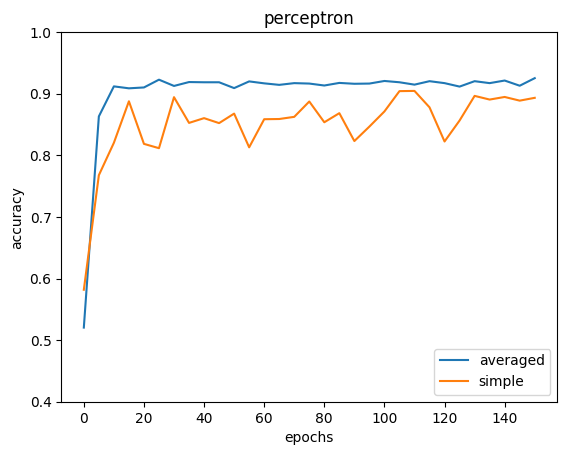

In [14]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.title("perceptron")
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.ylim(0.4, 1)

plt.plot(xs, ys_averaged, label="averaged")
plt.plot(xs, ys_simple, label="simple")
plt.legend(loc=4)
plt.show()

### Zadatak 1: usporedba simple i averaged perceptrona

Srednja točnost na testnom skupu (40 ponovljenih pokusa, 50/50 podjela, bez bias stupca kao u ćeliji iznad), prosjek ± standardna devijacija:

| epohe | simple | averaged |
|-|-|-|
| 1 | 0.618 ± 0.212 | 0.425 ± 0.074 |
| 5 | 0.795 ± 0.135 | 0.868 ± 0.024 |
| 20 | 0.831 ± 0.124 | 0.913 ± 0.014 |
| 50 | 0.875 ± 0.068 | 0.918 ± 0.010 |
| 150 | 0.885 ± 0.042 | 0.917 ± 0.013 |

Koji je "bolji"? Averaged perceptron, već nakon nekoliko epoha.

- Točnost: za 5 i više epoha je viša za otprilike 3 do 8 postotnih bodova.
- Stabilnost: standardna devijacija je 3 do 9 puta manja. Simple perceptron nakon svake pogreške skoči na novi pravac, pa njegova točnost ovisi o tome na kojem je primjeru učenje stalo. Podaci nisu skalirani i nisu linearno savršeno separabilni, pa simple perceptron nikad ne konvergira i neprestano "oscilira". Averaged perceptron uzima prosjek svih težina kroz učenje, što te skokove izglađuje.
- Iznimka: nakon samo jedne epohe averaged je lošiji, jer prosjek još sadrži nasumične početne težine i rane, loše težine. Taj učinak nestaje dodavanjem epoha.
- Cijena: averaged zahtijeva dodatno zbrajanje vektora težina nakon svakog primjera i čuva jedan dodatni vektor, što je zanemarivo u odnosu na dobitak.

###  Primjer s 2D ulazom

Možemo vizualizirati skup podataka u ravnini - 2D prostoru. U ovom slučaju klasifikacija se svodi na "povlačenje" pravca koji dijeli jednu klasu od druge (*binarna klasifikacija*).

<br>

**Zašto pravac?**
>  Perceptron može klasificirati samo linearno separabilne skupove zato što implementira skalarni produkt težina $\boldsymbol{w}$ i vektora $\boldsymbol{x}$ tj. *linearnu kombinaciju* značajki $x_i$.
>
> ➡️ "Povlačenje" najboljeg pravca odgovara pronalaženju najboljih težina.
> <br> <br>
> U višedimenzionalnim prostorima perceptron pronalazi **hiperravninu** - poopćenje pravca.
> - Hiperravnina uvijek dijeli prostor na dva dijela. Zbog toga ovakav jednostavni perceptron možemo koristiti samo za probleme binarne klasifikacije.




In [15]:
from sklearn.datasets import make_blobs

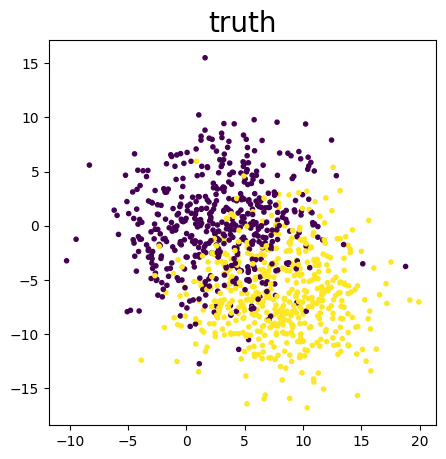

In [16]:
X, y = make_blobs(n_features=2, centers=2, n_samples=1000, random_state=18, cluster_std=4)

fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.scatter(X[:, 0], X[:, 1], c=y, marker=".")
ax.set_title('truth', fontsize=20)
plt.show()

In [17]:
new_simple = SimplePerceptron()
b = np.ones_like(y)  # bias
X_with_bias = np.column_stack((X, b))  # gets glued to data
new_simple.fit(X_with_bias, y)

In [18]:
new_simple.weights

array([  5.51319813,  -3.77037284, -30.87937273])

In [19]:
print(new_simple.evaluate(X_with_bias, y))
y_predicted = new_simple.predict(X_with_bias)

0.799


In [20]:
def calc_hyperplane(X, w):
    return np.ravel([-(w[2] + x * w[0]) / w[1] for x in X])

In [21]:
calc_hyperplane([0,10], new_simple.weights)

array([-8.19000508,  6.43241653])

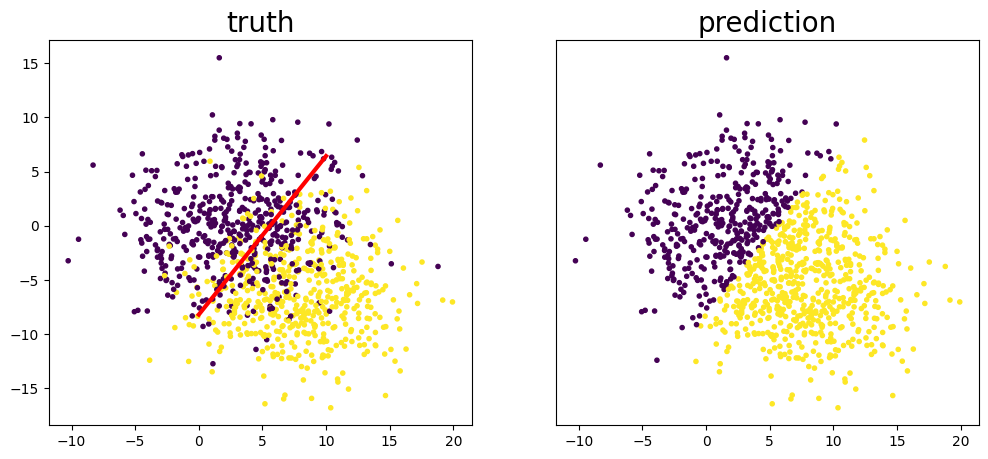

In [22]:
# Visualize results
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(X[:, 0], X[:, 1], c=y, marker=".")
ax[0].plot([0, 10], calc_hyperplane([0,10], new_simple.weights), lw=3, c='red')
ax[0].set_title('truth', fontsize=20)

ax[1].scatter(X[:, 0], X[:, 1], c=y_predicted, marker=".")
ax[1].set_xlim(ax[0].get_xlim())
ax[1].set_ylim(ax[0].get_ylim())
ax[1].set_yticks([])
ax[1].set_title('prediction', fontsize=20,)

plt.show()

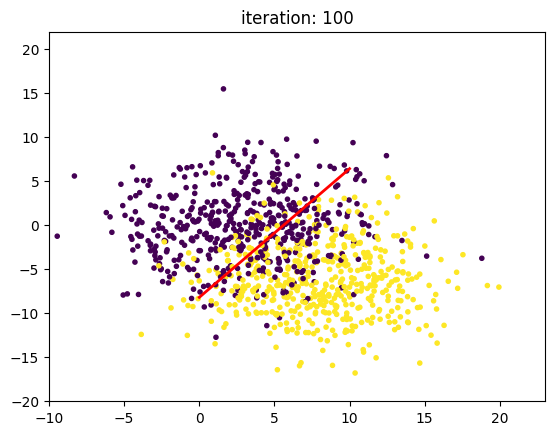

In [23]:
import time
from IPython import display

fig, ax = plt.subplots()

for i, the_weights in enumerate(new_simple.weight_history):
    plt.cla()
    # ax.axhline(y=0, color='k', alpha=0.1)
    # ax.axvline(x=0, color='k', alpha=0.1)
    plt.scatter(X[:, 0], X[:, 1], c=y, marker=".")
    plt.plot([0, 10], calc_hyperplane([0,10], the_weights), lw=2, c='red')
    plt.xlim([-10,23])
    plt.ylim([-20, 22])
    plt.title("iteration: {}".format(i+1))
    display.display(plt.gcf())
    display.clear_output(wait=True)
    time.sleep(1)

## Zadatak 2

### Kako perceptron uči (geometrijska interpretacija)

Skup težina $\boldsymbol{w}$ definira hiperravninu $\langle \boldsymbol{w}, \boldsymbol{x}\rangle = 0$ koja prolazi ishodištem, a $\boldsymbol{w}$ je njezin normalni vektor (okomit na nju). Točke za koje je $\langle \boldsymbol{w}, \boldsymbol{x}\rangle \geq 0$ leže na strani na koju pokazuje $\boldsymbol{w}$ i klasificiraju se kao 1, a ostale kao 0. Kut između $\boldsymbol{w}$ i $\boldsymbol{x}$ je manji od $90^\circ$ upravo onda kad je skalarni produkt pozitivan.

Učenje je pomicanje te hiperravnine, a događa se samo kad je primjer pogrešno klasificiran, pravilom $\boldsymbol{w} \leftarrow \boldsymbol{w} + \eta\,(y - \hat{y})\,\boldsymbol{x}$:

- Primjer klase 1 klasificiran kao 0 ($y - \hat{y} = 1$): $\boldsymbol{w}$ se pomiče *prema* $\boldsymbol{x}$, kut među njima se smanjuje, a točka se približava ispravnoj strani ravnine.
- Primjer klase 0 klasificiran kao 1 ($y - \hat{y} = -1$): $\boldsymbol{w}$ se pomiče *od* $\boldsymbol{x}$, kut raste, a točka prelazi na drugu stranu.
- Ispravno klasificirani primjeri: $y - \hat{y} = 0$, težine se ne mijenjaju.

Ako su klase linearno separabilne, ponavljanjem ovog postupka perceptron u konačno mnogo koraka pronalazi hiperravninu koja ih savršeno razdvaja (teorem o konvergenciji perceptrona). Stopa učenja $\eta$ određuje koliko se jako ravnina zakrene u jednom koraku. Ako klase nisu separabilne, težine neprestano osciliraju, što je razlog zašto averaged perceptron radi bolje.

### Kako iz težina dobiti 2D pravac

Za dvije značajke i težine $\boldsymbol{w} = (w_1, w_2, b)$ (zadnja težina množi ulaz $1$) granica odluke je skup točaka za koje je

$$w_1 x_1 + w_2 x_2 + b = 0 \quad\Longrightarrow\quad x_2 = -\frac{w_1}{w_2}\,x_1 - \frac{b}{w_2}, \qquad w_2 \neq 0.$$

To je pravac s koeficijentom smjera $k = -w_1/w_2$ i odsječkom na osi $x_2$ jednakim $l = -b/w_2$. Upravo to računa funkcija `calc_hyperplane` (`-(w[2] + x * w[0]) / w[1]`). Vektor $(w_1, w_2)$ je normala na taj pravac i pokazuje prema području klase 1.

### Čemu služi bias?

Bez biasa je granica odluke $w_1 x_1 + w_2 x_2 = 0$, tj. pravac koji uvijek prolazi ishodištem; mogao bi se samo rotirati. Bias $b$ pomiče pravac paralelno od ishodišta (odsječak $-b/w_2$), pa perceptron može odvojiti i klase čije se granica ne nalazi u ishodištu. Ekvivalentno, bias je prag aktivacije: neuron se aktivira kad je $\langle \boldsymbol{w}, \boldsymbol{x}\rangle \geq -b$. Implementira se dodavanjem konstantnog ulaza $1$ svakom primjeru (kao u ćeliji `np.column_stack((X, b))`), a njegova težina uči se kao i sve ostale.